# LiveCodeBench results figures

The figures use the main experiment's paired analysis and generation counts. Run all cells from the repository root or from the `results` directory. The notebook requires Matplotlib and uses the repository's existing results files.

ChatGPT assisted with writing the plotting code and creating this notebook.


In [1]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt

results_dir = Path("results") if Path("results/analysis").is_dir() else Path(".")
analysis_dir = results_dir / "analysis" / "main_20261116"

with (analysis_dir / "analysis.json").open() as file:
    analysis = json.load(file)

with (analysis_dir / "summary.csv").open() as file:
    outcomes = {(row["model"], row["condition"]): row for row in csv.DictReader(file)}

model_names = {
    "anthropic": "Claude Haiku 5.5",
    "deepseek": "DeepSeek Flash",
    "openai": "GPT-6 Luna",
}

plt.rcParams.update({"font.size": 11, "pdf.fonttype": 42,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.spines.left": False})


## Figure 1. Paired pass-rate differences

Points show the estimated differences. Bars show unadjusted 95% bootstrap confidence intervals. The all-attempts analysis counts technical failures as unsuccessful.

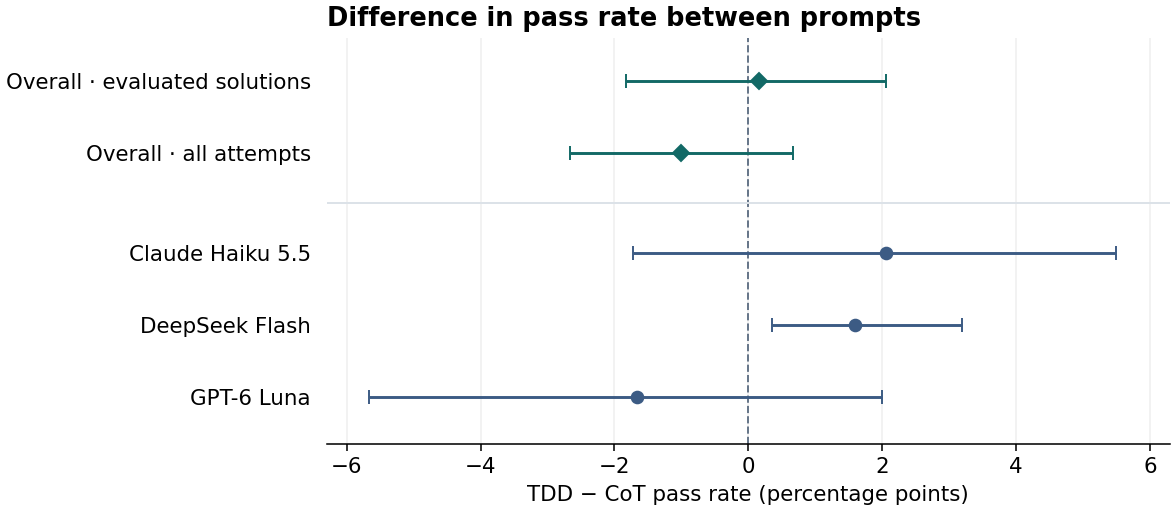

In [2]:
rows = [
    ("Overall · evaluated solutions", analysis["overall"]),
    ("Overall · all attempts", analysis["sensitivity_technical_as_failure"]),
]
rows.extend((name, analysis["models"][key]) for key, name in model_names.items())
positions = [4.4, 3.4, 2, 1, 0]

fig, ax = plt.subplots(figsize=(8.4, 3.65), layout="constrained")
ax.axvline(0, color="#657488", linewidth=1, linestyle="--")
ax.axhline(2.7, color="#dce2e8", linewidth=1)

for index, (position, (_, stats)) in enumerate(zip(positions, rows)):
    effect = stats["tdd_minus_cot_pp"]
    lower, upper = stats["cluster_bootstrap_95ci_pp"]
    overall = index < 2
    ax.errorbar(
        effect, position, xerr=[[effect - lower], [upper - effect]],
        fmt="D" if overall else "o", capsize=3.5,
        color="#126966" if overall else "#3c5b84",
    )

ax.set(
    yticks=positions, yticklabels=[name for name, _ in rows],
    xlim=(-6.3, 6.3), ylim=(-0.65, 5), xticks=range(-6, 7, 2),
    xlabel="TDD − CoT pass rate (percentage points)",
)
ax.set_title("Difference in pass rate between prompts", loc="left", fontweight="bold")
ax.tick_params(axis="y", length=0, pad=8)
ax.grid(axis="x", alpha=0.2)
plt.show()


## Figure 2. Generation outcomes

Each bar represents 300 attempts. Technical failures include API errors and truncated responses.

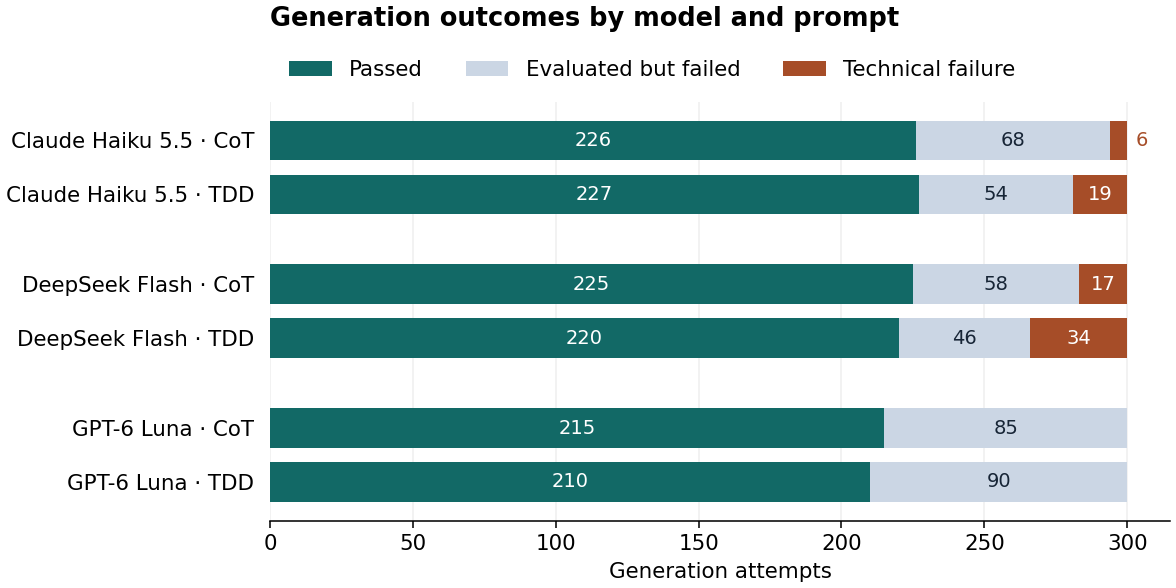

In [3]:
categories = ["Passed", "Evaluated but failed", "Technical failure"]
colors = ["#126966", "#cbd6e4", "#a64d28"]
positions = [6.6, 5.7, 4.2, 3.3, 1.8, 0.9]
pairs = [(model, prompt) for model in model_names for prompt in ("cot", "tdd")]

fig, ax = plt.subplots(figsize=(8.4, 4.2), layout="constrained")
labels = []
for index, (position, (model, prompt)) in enumerate(zip(positions, pairs)):
    row = outcomes[model, prompt]
    passed, evaluated, technical = (
        int(row[key]) for key in ("passed", "evaluated", "technical_errors")
    )
    counts = [passed, evaluated - passed, technical]
    assert sum(counts) == int(row["attempts_total"]) == 300
    labels.append(f"{model_names[model]} · {'CoT' if prompt == 'cot' else 'TDD'}")

    left = 0
    for count, color, category in zip(counts, colors, categories):
        ax.barh(position, count, left=left, height=0.66, color=color,
                label=category if index == 0 else None)
        if count:
            inside = count >= 16
            ax.text(left + count / 2 if inside else 303, position, str(count),
                    ha="center" if inside else "left", va="center",
                    color="#172536" if color == colors[1] else "white" if inside else color,
                    fontsize=10)
        left += count

ax.set(yticks=positions, yticklabels=labels, xlim=(0, 315),
       xticks=range(0, 301, 50), xlabel="Generation attempts")
ax.set_title("Generation outcomes by model and prompt", loc="left", fontweight="bold", pad=39)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.005), ncol=3, frameon=False)
ax.tick_params(axis="y", length=0, pad=8)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
plt.show()


## Figure 3. Token usage, cost, and latency

Token usage combines the recorded input and output token totals. Cost is the recorded total for each model and prompt. Latency is the recorded mean in seconds. Each model–prompt condition scheduled 300 attempts, and the figure uses the resource metrics as reported in the main-run analysis.

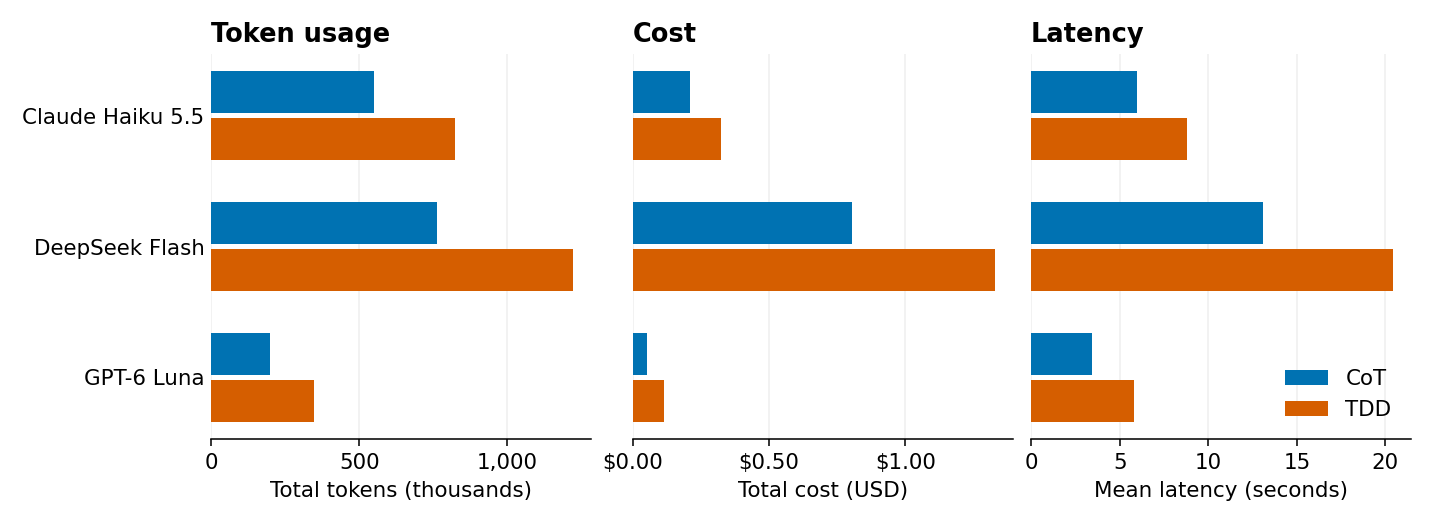

In [4]:
from matplotlib.ticker import StrMethodFormatter

metrics = [
    ("Token usage", "Total tokens (thousands)", "{x:,.0f}",
     lambda rates: (rates["input_tokens_total"] + rates["output_tokens_total"]) / 1000),
    ("Cost", "Total cost (USD)", "${x:.2f}", lambda rates: rates["cost_usd_total"]),
    ("Latency", "Mean latency (seconds)", "{x:.0f}",
     lambda rates: rates["latency_seconds_mean"]),
]

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), sharey=True, layout="constrained")
positions = list(range(len(model_names)))

for ax, (title, label, tick_format, metric) in zip(axes, metrics):
    for prompt, offset, color in [("CoT", -0.18, "#0072B2"), ("TDD", 0.18, "#D55E00")]:
        values = [
            metric(analysis["models"][model]["rates"][prompt.lower()])
            for model in model_names
        ]
        ax.barh([position + offset for position in positions], values,
                height=0.32, color=color, label=prompt)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel(label)
    ax.xaxis.set_major_formatter(StrMethodFormatter(tick_format))
    ax.tick_params(axis="y", length=0)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)

axes[0].set_yticks(positions, model_names.values())
axes[0].invert_yaxis()
axes[-1].legend(frameon=False, loc="lower right")
plt.show()
